# 1) Document Loading

In [1]:
import os

In [2]:
doc_folder_names = ['tickets', 'runbooks', 'product-docs']

In [3]:
root_dir_path = '5_checkpoint_project/corpus'
root_dir = os.listdir(root_dir_path)

In [4]:
for folder in doc_folder_names:
    folder_path = root_dir_path + '/' + folder
    print(folder_path)
    filenames = os.listdir(folder_path)
    #print(filenames)

5_checkpoint_project/corpus/tickets
5_checkpoint_project/corpus/runbooks
5_checkpoint_project/corpus/product-docs


In [5]:
import os

doc_folder_names = ['tickets', 'runbooks', 'product-docs']
root_dir_path = '5_checkpoint_project/corpus'

all_file_paths = []

for folder in doc_folder_names:
    folder_path = os.path.join(root_dir_path, folder)
    for dirpath, dirnames, filenames in os.walk(folder_path):
        for filename in filenames:
            # Skip hidden files like .DS_Store
            if not filename.startswith('.'):
                all_file_paths.append(os.path.join(dirpath, filename))

print(f"Found {len(all_file_paths)} files")
for path in all_file_paths:
    print(path)

Found 100 files
5_checkpoint_project/corpus/tickets/ticket-1455-cant-access-billing.html
5_checkpoint_project/corpus/tickets/ticket-1189-401-with-valid-key.html
5_checkpoint_project/corpus/tickets/ticket-1349-export-stuck.html
5_checkpoint_project/corpus/tickets/ticket-1421-ios-crash.html
5_checkpoint_project/corpus/tickets/ticket-1378-missing-data-in-export.html
5_checkpoint_project/corpus/tickets/ticket-1156-api-rate-limit-confusion.html
5_checkpoint_project/corpus/tickets/ticket-1322-downgrade-question.html
5_checkpoint_project/corpus/tickets/ticket-1267-integration-disconnect.html
5_checkpoint_project/corpus/tickets/ticket-1078-password-reset-not-arriving.html
5_checkpoint_project/corpus/tickets/ticket-1301-unexpected-charge.html
5_checkpoint_project/corpus/tickets/ticket-1042-sso-redirect-loop.html
5_checkpoint_project/corpus/tickets/ticket-1402-slow-execution.html
5_checkpoint_project/corpus/tickets/ticket-1289-schedule-not-running.html
5_checkpoint_project/corpus/tickets/ticket-

In [6]:
file_grouping = {}
for path in all_file_paths:
    file_type = path.split('.')[-1]
    if file_type not in file_grouping:
        file_grouping[file_type] = [path]
    else:
        file_grouping[file_type].append(path)

In [7]:
file_grouping.keys()

dict_keys(['html', 'pdf', 'md'])

In [8]:
for key in file_grouping:
    print(key, len(file_grouping[key]))

html 15
pdf 25
md 60


## HTML data loading

In [9]:
test_file_path = file_grouping['html'][0]

In [10]:
#for html files
from langchain_community.document_loaders import BSHTMLLoader

loader = BSHTMLLoader(test_file_path)
docs = loader.load()

# Metadata includes {"source": "./my_file.html", "title": "Page Title Here"}
print(docs[0].metadata)

/var/folders/fn/s661_g5n311_1tgvg_11bq000000gn/T/ipykernel_72569/2302699163.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import BSHTMLLoader


{'source': '5_checkpoint_project/corpus/tickets/ticket-1455-cant-access-billing.html', 'title': "HX-1455 — Editor can't see Billing settings — bug?"}


In [11]:
len(docs)

1

In [12]:
print(docs[0].page_content)




HX-1455 — Editor can't see Billing settings — bug?




TICKET HX-1455
Editor can't see Billing settings — bug?

Status: Resolved
Category: Permissions
Priority: P3
Customer: Carlos Mendoza (Cedar Valley Co-op)
Agent: Marcus Webb





Carlos Mendoza
Customer
2024-04-19 14:08 UTC

I'm an Editor in our workspace and I need to update our payment method. I don't see Billing under Settings. The owner says he can see it. Is something broken?



Marcus Webb
Helix Support
2024-04-19 14:21 UTC

Hi Carlos — not a bug. Billing is restricted to the workspace Owner role only. Even Admins don't see it. The four roles are Owner, Admin, Editor, Viewer, and only Owner has billing access.If you need to change the payment method, you have two options: (1) ask the Owner to make the change, or (2) ask the Owner to transfer ownership to you (only one Owner per workspace, so they'd lose Owner status). Most teams go with option 1 unless ownership transfer is a deliberate decision.



Carlos Mendoza
Customer

In [13]:
html_docs = []
for html_path in file_grouping['html']:
    html_loader = BSHTMLLoader(html_path)
    html_doc = html_loader.load()
    html_docs += html_doc

In [14]:
len(html_docs)

15

In [15]:
html_docs[0]

Document(metadata={'source': '5_checkpoint_project/corpus/tickets/ticket-1455-cant-access-billing.html', 'title': "HX-1455 — Editor can't see Billing settings — bug?"}, page_content="\n\n\nHX-1455 — Editor can't see Billing settings — bug?\n\n\n\n\nTICKET HX-1455\nEditor can't see Billing settings — bug?\n\nStatus: Resolved\nCategory: Permissions\nPriority: P3\nCustomer: Carlos Mendoza (Cedar Valley Co-op)\nAgent: Marcus Webb\n\n\n\n\n\nCarlos Mendoza\nCustomer\n2024-04-19 14:08 UTC\n\nI'm an Editor in our workspace and I need to update our payment method. I don't see Billing under Settings. The owner says he can see it. Is something broken?\n\n\n\nMarcus Webb\nHelix Support\n2024-04-19 14:21 UTC\n\nHi Carlos — not a bug. Billing is restricted to the workspace Owner role only. Even Admins don't see it. The four roles are Owner, Admin, Editor, Viewer, and only Owner has billing access.If you need to change the payment method, you have two options: (1) ask the Owner to make the change, o

In [16]:
html_docs[1]

Document(metadata={'source': '5_checkpoint_project/corpus/tickets/ticket-1189-401-with-valid-key.html', 'title': 'HX-1189 — Getting 401 errors with what should be a valid API key'}, page_content="\n\n\nHX-1189 — Getting 401 errors with what should be a valid API key\n\n\n\n\nTICKET HX-1189\nGetting 401 errors with what should be a valid API key\n\nStatus: Resolved\nCategory: API\nPriority: P1\nCustomer: Jakob Andersen (Skylane Aviation)\nAgent: Devon Park\n\n\n\n\n\nJakob Andersen\nCustomer\n2024-03-22 08:11 UTC\n\nMy production integration started failing at 3am UTC with 401 unauthorized. Key hasn't been rotated. Nothing changed on our side. We're partly down.\n\n\n\nDevon Park\nHelix Support\n2024-03-22 08:19 UTC\n\nHi Jakob — looking into this immediately. What's the prefix of the key (just the first 12 chars, don't share the full key)?\n\n\n\nJakob Andersen\nCustomer\n2024-03-22 08:21 UTC\n\nhlx_live_8a3f4...\n\n\n\nDevon Park\nHelix Support\n2024-03-22 08:32 UTC\n\nFound it. That 

## PDF data loading

In [17]:
from langchain_community.document_loaders import PyPDFLoader 
from langchain_core.documents import Document

In [18]:
pdf_docs = []
i = 0
for pdf_path in file_grouping['pdf']:
    pdf_loader = PyPDFLoader(pdf_path)
    pdf_doc = pdf_loader.load()
    pdf_docs += pdf_doc

In [19]:
print(pdf_docs[0].page_content)

Auth Service Degradation
INTERNAL — Helix Engineering / CS Operations
SCOPE
This runbook covers degradation of the auth-service — the service that issues and validates user
sessions and API tokens. Auth-service downtime locks all users out of the platform.
DETECTION
Auth-service exposes /health and /ready endpoints. Synthetic probes alert on degradation.
Customer-reported login failures are also a strong signal.
STEP 1 — Confirm scope
Test login from an internal account. If you cannot log in, the impact is total. If you can log in but specific
users cannot, the issue may be data-side (corrupted user record, IdP misconfiguration on customer
side).
STEP 2 — Check downstream
Auth-service depends on Postgres (user store) and Redis (session cache). Check both. If Postgres is
degraded, see database-failover. If Redis is degraded, restart redis-auth pods one by one.
STEP 3 — Roll back recent deploys
If a deploy in the last 30 minutes correlates with the issue, roll back: `helix deploy rollbac

## Markdown file reading

In [20]:
from langchain_community.document_loaders import UnstructuredMarkdownLoader

In [21]:
md_docs = []
for md_path in file_grouping['md']:
    md_loader = UnstructuredMarkdownLoader(md_path, mode = 'single')
    md_doc = md_loader.load()
    md_docs += md_doc

In [22]:
len(md_docs)

60

In [23]:
# Add doc_type metadata to each category
for doc in html_docs:
    doc.metadata['doc_type'] = 'ticket'

for doc in pdf_docs:
    doc.metadata['doc_type'] = 'runbook'

for doc in md_docs:
    doc.metadata['doc_type'] = 'product-doc'

In [24]:
# be more granular with the runbooks and product docs (
#     since they have subcategories like incident-response, customer-ops, csm, engineering
# )

In [25]:
for doc in pdf_docs:
    doc.metadata['doc_type'] = 'runbook'
    # Extract subcategory from path like "runbooks/incident-response/file.pdf"
    path_parts = doc.metadata['source'].split('/')
    if 'runbooks' in path_parts:
        idx = path_parts.index('runbooks')
        if idx + 1 < len(path_parts):
            doc.metadata['category'] = path_parts[idx + 1]

In [26]:
for doc in md_docs:
    doc.metadata['doc_type'] = 'product-doc'
    path_parts = doc.metadata['source'].split('/')
    if 'product-docs' in path_parts:
        idx = path_parts.index('product-docs')
        if idx + 1 < len(path_parts):
            doc.metadata['category'] = path_parts[idx + 1]

In [27]:
all_docs = html_docs + pdf_docs + md_docs

In [28]:
len(all_docs)

101

In [29]:
md_docs[55].metadata

{'source': '5_checkpoint_project/corpus/product-docs/billing/usage-and-overages.md',
 'doc_type': 'product-doc',
 'category': 'billing'}

In [30]:
pdf_docs[10].metadata

{'producer': 'PyPDF',
 'creator': 'PyPDF',
 'creationdate': '2026-05-08T00:57:34+00:00',
 'title': 'custom-sla-handling',
 'moddate': '2026-05-08T00:57:34+00:00',
 'source': '5_checkpoint_project/corpus/runbooks/customer-ops/custom-sla-handling.pdf',
 'total_pages': 1,
 'page': 0,
 'page_label': '1',
 'doc_type': 'runbook',
 'category': 'customer-ops'}

# 2) Chunking

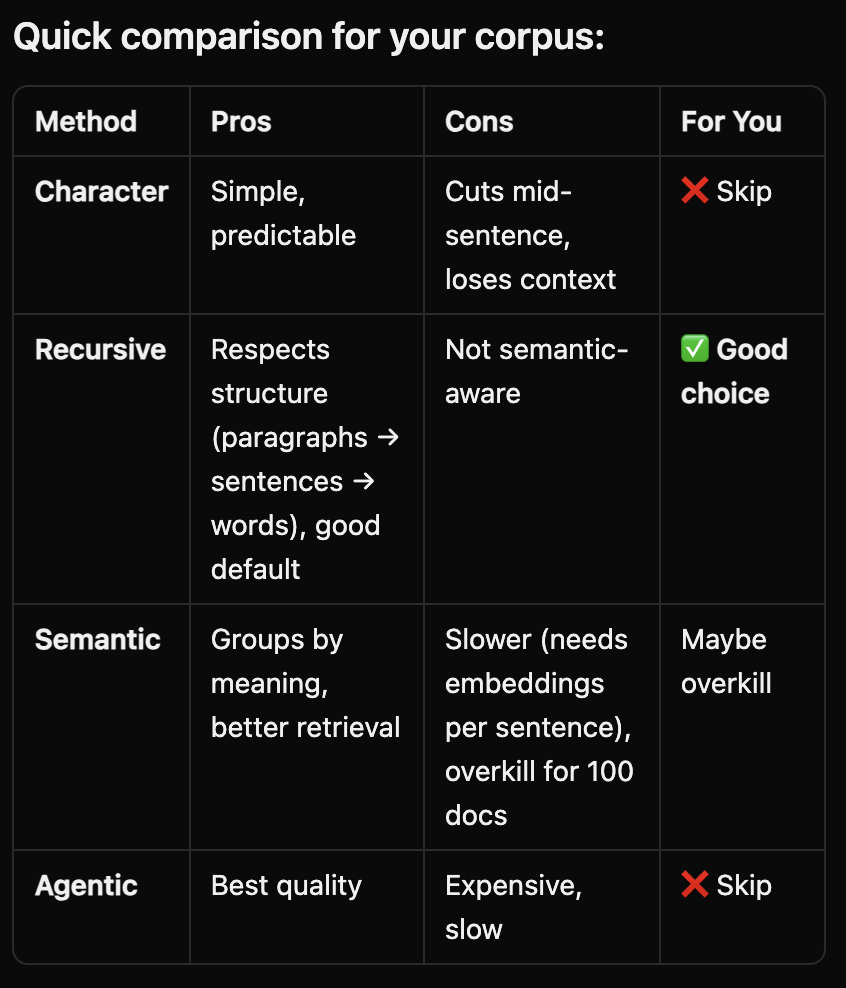

**Why Recursive works well for you:**
- Your docs have natural structure — tickets have conversation threads, runbooks have steps, product docs have sections with headers
- Recursive will split on \n\n first (paragraph breaks), then \n, then sentences — preserves logical units
- 100 docs is small — you won't see huge gains from semantic chunking

**One thing you're missing: Markdown/HTML-aware splitters
Since you have structured docs, consider:**

- from langchain_text_splitters import MarkdownTextSplitter, HTMLHeaderTextSplitter
- These split by headers (#, ##, h1, etc.) which can preserve document structure better than generic recursive.

In [31]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)

chunks = text_splitter.split_documents(all_docs)
print(f"Split {len(all_docs)} docs into {len(chunks)} chunks")

Split 101 docs into 196 chunks


In [32]:
import hashlib

for chunk in chunks:
    # Create unique ID from content hash
    chunk_id = hashlib.md5(chunk.page_content.encode()).hexdigest()
    chunk.metadata['id'] = chunk_id

In [33]:
chunks[0]

Document(metadata={'source': '5_checkpoint_project/corpus/tickets/ticket-1455-cant-access-billing.html', 'title': "HX-1455 — Editor can't see Billing settings — bug?", 'doc_type': 'ticket', 'id': 'db1e4413223f758eb6b93904c77c3fbb'}, page_content="HX-1455 — Editor can't see Billing settings — bug?\n\n\n\n\nTICKET HX-1455\nEditor can't see Billing settings — bug?\n\nStatus: Resolved\nCategory: Permissions\nPriority: P3\nCustomer: Carlos Mendoza (Cedar Valley Co-op)\nAgent: Marcus Webb\n\n\n\n\n\nCarlos Mendoza\nCustomer\n2024-04-19 14:08 UTC\n\nI'm an Editor in our workspace and I need to update our payment method. I don't see Billing under Settings. The owner says he can see it. Is something broken?\n\n\n\nMarcus Webb\nHelix Support\n2024-04-19 14:21 UTC\n\nHi Carlos — not a bug. Billing is restricted to the workspace Owner role only. Even Admins don't see it. The four roles are Owner, Admin, Editor, Viewer, and only Owner has billing access.If you need to change the payment method, you

In [34]:
from dotenv import load_dotenv
load_dotenv()

True

In [35]:
from langchain_openai import OpenAIEmbeddings
from langchain_pinecone import PineconeVectorStore
from pinecone import Pinecone, ServerlessSpec

/Users/raghavmanoharanjayanthi/Downloads/BASWE_AI_Learning_Roadmap/Module_1_LLMs_and_RAG/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**SET UP OPEN AI and PINECONE api keys in .env file before running next cells**

In [36]:
# Initialize embeddings
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# Initialize Pinecone client
pc = Pinecone()

In [37]:
import os
print(os.getenv("PINECONE_API_KEY")[:10])  # Print first 10 chars to confirm it loaded

pcsk_1MwMm


In [38]:
# # Create index (only need to do this once)
# index_name = "helix-support-two"  # or whatever you want to call it

# # Check if index exists, if not create it
# if index_name not in pc.list_indexes().names():
#     pc.create_index(
#         name=index_name,
#         dimension=1536,  # text-embedding-3-small dimension
#         metric="cosine",
#         spec=ServerlessSpec(
#             cloud="aws",
#             region="us-east-1"  # or your preferred region
#         )
#     )

# # Create vector store and add documents
# vectorstore = PineconeVectorStore.from_documents(
#     documents=chunks,  # your chunked documents
#     embedding=embeddings,
#     index_name=index_name
# )

In [39]:
# Connect to existing index — data is already there
vectorstore = PineconeVectorStore(
    index_name="helix-support-two",
    embedding=embeddings
)

# Retriever

In [40]:
results = vectorstore.similarity_search("How do I reset my password?", k=3)

In [41]:
len(results)

3

In [42]:
for r in results:
    print(r.id, r.metadata, r.page_content)
    print('----------------------------------------')

aa7d74e3-3b85-4587-95ec-0933e155931b {'doc_type': 'ticket', 'id': 'e4ade72f17bd09cb95a2a36e8711d553', 'source': '5_checkpoint_project/corpus/tickets/ticket-1078-password-reset-not-arriving.html', 'title': 'HX-1078 — Password reset email never arrives'} HX-1078 — Password reset email never arrives




TICKET HX-1078
Password reset email never arrives

Status: Resolved
Category: Authentication
Priority: P2
Customer: Tom Reilly (Bluefin Brewing)
Agent: Sandra Liu





Tom Reilly
Customer
2024-03-15 14:22 UTC

I've been trying to reset my password for the last hour. I click 'forgot password,' enter my email, get the success message, but no email ever arrives. Checked spam. Tried different browsers. Nothing.



Sandra Liu
Helix Support
2024-03-15 14:38 UTC

Hi Tom — let me look into this. Can you confirm the email address you're using? I want to check our delivery logs against it.



Tom Reilly
Customer
2024-03-15 14:41 UTC

tom@bluefinbrewing.com



Sandra Liu
Helix Support
2024-03-15 14:5

In [43]:
#from langchain.retrievers import BM25Retriever
from langchain_community.retrievers import BM25Retriever
retriever = BM25Retriever.from_documents(chunks)
retriever.k = 3

In [44]:
#from langchain.retrievers import BM25Retriever

In [45]:
bm_25_results = retriever.invoke("How do I reset my password?")

In [46]:
len(bm_25_results)

3

In [47]:
bm_25_results[0]

Document(metadata={'source': '5_checkpoint_project/corpus/tickets/ticket-1078-password-reset-not-arriving.html', 'title': 'HX-1078 — Password reset email never arrives', 'doc_type': 'ticket', 'id': 'e4ade72f17bd09cb95a2a36e8711d553'}, page_content="HX-1078 — Password reset email never arrives\n\n\n\n\nTICKET HX-1078\nPassword reset email never arrives\n\nStatus: Resolved\nCategory: Authentication\nPriority: P2\nCustomer: Tom Reilly (Bluefin Brewing)\nAgent: Sandra Liu\n\n\n\n\n\nTom Reilly\nCustomer\n2024-03-15 14:22 UTC\n\nI've been trying to reset my password for the last hour. I click 'forgot password,' enter my email, get the success message, but no email ever arrives. Checked spam. Tried different browsers. Nothing.\n\n\n\nSandra Liu\nHelix Support\n2024-03-15 14:38 UTC\n\nHi Tom — let me look into this. Can you confirm the email address you're using? I want to check our delivery logs against it.\n\n\n\nTom Reilly\nCustomer\n2024-03-15 14:41 UTC\n\ntom@bluefinbrewing.com\n\n\n\nSa

In [48]:
bm_25_results[0].metadata['id']

'e4ade72f17bd09cb95a2a36e8711d553'

In [49]:
bm_25_results[1].metadata['id']

'8617d7e4a9a3b41f6832ac9bcaeaf0bb'

In [50]:
results[1].metadata['id']

'8617d7e4a9a3b41f6832ac9bcaeaf0bb'

In [51]:
results[1].id

'13539537-53bf-4320-b8b7-8b3533ebde22'

In [52]:
bm_25_results[2]

Document(metadata={'source': '5_checkpoint_project/corpus/tickets/ticket-1349-export-stuck.html', 'title': "HX-1349 — Data export stuck in 'pending' state for 2 days", 'doc_type': 'ticket', 'id': '0a134325345404f902fb2020a6fd1f19'}, page_content="Devon Park\nHelix Support\n2024-04-09 08:32 UTC\n\nExport download URLs expire 24 hours after generation, but each export's clock starts independently. The one showing expired likely finished earliest. Check the timestamp of the email — if it's >24h, that's expected. I can regenerate the URL on my end; the export file itself is retained for 7 days. Want me to do that?\n\n\n\nHassan Mubarak\nCustomer\n2024-04-09 08:36 UTC\n\nYes please.\n\n\n\nDevon Park\nHelix Support\n2024-04-09 08:41 UTC\n\nFresh URL sent to your email. Good for another 24 hours.\n\n\n\nRESOLUTION\nCustomer's full-history export of 12.4M records was running slowly (~4M/day, estimated 3 days). Recommended cancelling and filing 4 parallel exports chunked by 3-month date ranges

In [53]:
seen_ids = set()
combined = []
for doc in results + bm_25_results:
    doc_id = doc.metadata.get('id')  # Use metadata['id'], not .id
    if doc_id not in seen_ids:
        seen_ids.add(doc_id)
        combined.append(doc)

In [54]:
len(combined)

4

In [55]:
len(results), len(bm_25_results)

(3, 3)

In [56]:
def get_documents(query):
    vector_results = vectorstore.similarity_search(query, k=3)
    bm25_results = retriever.invoke(query)

    seen_ids = set()
    combined = []
    for doc in vector_results + bm25_results:
        doc_id = doc.metadata.get('id')
        if doc_id not in seen_ids:
            seen_ids.add(doc_id)
            combined.append(doc)

    return combined

# Generation

In [57]:
from langchain_openai import ChatOpenAI
from langsmith import traceable

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

In [58]:
from pydantic import BaseModel
from typing import Literal

class RAGResponse(BaseModel):
    answer: str
    sources: list[str]
    confidence: Literal["low", "medium", "high"]

structured_llm = llm.with_structured_output(RAGResponse)

In [59]:
@traceable
def generate_answer(question):
    relevant_documents = get_documents(question)
    #print(len(relevant_documents))
    docs_string = "\n\n".join(
        #f"[DOC_ID: {doc.metadata.get('id')}]\n{doc.page_content}"
        f"[DOC_ID: {doc.metadata.get('id')}]\n{doc.page_content}"
        for doc in docs
    )

    # instructions = f"""You are a helpful assistant who is good at analyzing source information and answering questions.
    #    Use the following source documents to answer the user's questions.
    #    If you don't know the answer, just say that you don't know.
    #    Use three sentences maximum and keep the answer concise.
    # """

    # context = f"RELEVANT CONTEXT: {docs_string}, USER QUESTION: {question}"

    # ai_msg = llm.invoke([
    #         {"role": "system", "content": instructions},
    #         {"role": "user", "content": context},
    #     ],
    # )
    # instructions = f"""You are a helpful assistant who is good at analyzing source information and answering questions.
    # Use the following source documents to answer the user's questions.
    # If you don't know the answer, just say that you don't know.
    # Use three sentences maximum and keep the answer concise.
    # <context>
    # {docs_string}
    # </context>"""
    instructions = f"""You are a helpful assistant who is good at analyzing source information and answering questions.
    Use the following source documents to answer the user's questions.
    If you don't know the answer, just say that you don't know.
    Use three sentences maximum and keep the answer concise.
    
    <context>
    {docs_string}
    </context>"""
    
    ai_msg = structured_llm.invoke([
        {"role": "system", "content": instructions},
        {"role": "user", "content": question},
    ])
    
    return {"output": ai_msg, "documents": docs, 'doc_string': docs_string}
    
    #return docs_string

In [60]:
@traceable
def generate_answer(question):
    docs = get_documents(question)
    docs_string = "\n\n".join(
        f"[DOC_ID: {doc.metadata.get('id')}]\n{doc.page_content}"
        for doc in docs
    )
    
    instructions = f"""You are a helpful assistant who is good at analyzing source information and answering questions.
Use the following source documents to answer the user's questions.
If you don't know the answer, just say that you don't know.
Use three sentences maximum and keep the answer concise.

<context>
{docs_string}
</context>"""
    
    ai_msg = structured_llm.invoke([
        {"role": "system", "content": instructions},
        {"role": "user", "content": question},
    ])
    
    return {"output": ai_msg, "documents": docs, 'doc_string': docs_string, 'instructions': instructions}

In [61]:
out = generate_answer('How do I reset my password?')

In [62]:
out['instructions']

"You are a helpful assistant who is good at analyzing source information and answering questions.\nUse the following source documents to answer the user's questions.\nIf you don't know the answer, just say that you don't know.\nUse three sentences maximum and keep the answer concise.\n\n<context>\n[DOC_ID: e4ade72f17bd09cb95a2a36e8711d553]\nHX-1078 — Password reset email never arrives\n\n\n\n\nTICKET HX-1078\nPassword reset email never arrives\n\nStatus: Resolved\nCategory: Authentication\nPriority: P2\nCustomer: Tom Reilly (Bluefin Brewing)\nAgent: Sandra Liu\n\n\n\n\n\nTom Reilly\nCustomer\n2024-03-15 14:22 UTC\n\nI've been trying to reset my password for the last hour. I click 'forgot password,' enter my email, get the success message, but no email ever arrives. Checked spam. Tried different browsers. Nothing.\n\n\n\nSandra Liu\nHelix Support\n2024-03-15 14:38 UTC\n\nHi Tom — let me look into this. Can you confirm the email address you're using? I want to check our delivery logs aga

In [143]:
out['output'].answer

"To reset your password, click on the 'forgot password' link on the login page, enter your email address, and follow the instructions sent to your email. If you do not receive the email, check your spam folder or contact support for assistance. Ensure your email provider is not blocking emails from the service."

In [63]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough, RunnableLambda

prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a helpful assistant who is good at analyzing source information and answering questions.
Use the following source documents to answer the user's questions.
If you don't know the answer, just say that you don't know.
Use three sentences maximum and keep the answer concise.
Return the DOC_IDs of the sources you used in your answer.

<context>
{context}
</context>"""),
    ("user", "{question}")
])

# Helper to format docs
def format_docs(docs):
    return "\n\n".join(
        f"[DOC_ID: {doc.metadata.get('id')}]\n{doc.page_content}"
        for doc in docs
    )

# LCEL Chain
rag_chain = (
    {
        "context": RunnableLambda(get_documents) | RunnableLambda(format_docs),
        "question": RunnablePassthrough()
    }
    | prompt
    | structured_llm
)

# Use it
response = rag_chain.invoke("How do I reset my password?")
print(response.answer)
print(response.sources)
print(response.confidence)


To reset your password, click on the 'forgot password' link and enter your email address. You should receive a password reset email; if it doesn't arrive, check your spam folder or contact support for assistance. If you encounter issues, your email provider may be rejecting the reset emails due to configuration problems.
['e4ade72f17bd09cb95a2a36e8711d553', '8617d7e4a9a3b41f6832ac9bcaeaf0bb']
high


In [64]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough, RunnableLambda

In [65]:
prompt = ChatPromptTemplate.from_messages([
    ('system', """You are a helpful assistant who is good at analyzing source information and answering questions.
Use the following source documents to answer the user's questions.
If you don't know the answer, just say that you don't know.
Use three sentences maximum and keep the answer concise.
Return the DOC_IDs of the sources you used in your answer.

<context>
{context}
</context>"""),
    ('user', "{question}")
])

In [66]:
# Helper to format docs
def format_docs(docs):
    return "\n\n".join(
        f"[DOC_ID: {doc.metadata.get('id')}]\n{doc.page_content}"
        for doc in docs
    )

In [67]:
rag_chain = (
    {
        'context': RunnableLambda(get_documents) | RunnableLambda(format_docs),
        'question': RunnablePassthrough()
    }
    | prompt
    | structured_llm
)

In [68]:
response = rag_chain.invoke("How do I reset my password?")

In [69]:
response.answer

"To reset your password, click on the 'forgot password' link on the login page and enter your email address. You will receive a password reset email; if it doesn't arrive, check your spam folder or contact support for assistance. Ensure your email provider is not blocking emails from the service."

In [70]:
response.sources

['e4ade72f17bd09cb95a2a36e8711d553', '8617d7e4a9a3b41f6832ac9bcaeaf0bb']

In [71]:
response.confidence

'high'

# Evaluation

In [95]:
# ============================================
# EVALUATORS
# ============================================

from pydantic import BaseModel, Field
import json
import pandas as pd
from datetime import datetime

# --- Pydantic Models for Structured Output ---

class FaithfulnessResult(BaseModel):
    claims: list[str] = Field(description="All factual claims in the answer")
    supported_claims: list[str] = Field(description="Claims supported by context")
    unsupported_claims: list[str] = Field(description="Claims NOT supported by context")
    score: float = Field(ge=0, le=1, description="supported_claims / total_claims")
    reasoning: str

class RelevanceResult(BaseModel):
    question_intent: str = Field(description="Core intent of the question")
    answer_addresses_intent: bool = Field(description="Does answer address the intent?")
    completeness: str = Field(description="full, partial, or none")
    score: float = Field(ge=0, le=1)
    reasoning: str

class CorrectnessResult(BaseModel):
    key_facts_required: list[str] = Field(description="Key facts from ground truth")
    key_facts_found: list[str] = Field(description="Key facts present in answer")
    key_facts_missing: list[str] = Field(description="Key facts missing from answer")
    score: float = Field(ge=0, le=1, description="found / required")
    reasoning: str

# --- Create LLMs with Structured Output ---

faithfulness_llm = llm.with_structured_output(FaithfulnessResult)
relevance_llm = llm.with_structured_output(RelevanceResult)
correctness_llm = llm.with_structured_output(CorrectnessResult)

# --- Evaluator Functions ---

def evaluate_faithfulness(answer: str, context: str) -> FaithfulnessResult:
    """Check if answer is grounded in the retrieved context."""
    prompt = f"""Evaluate if the answer is faithful to the provided context.
Faithful means: every factual claim in the answer can be traced back to the context.

<context>
{context}
</context>

<answer>
{answer}
</answer>

Instructions:
1. Extract all factual claims/statements from the answer
2. For each claim, check if the context supports it
3. Calculate score = len(supported_claims) / len(all_claims)
4. If answer says "I don't know" with no factual claims, score = 1.0
5. If answer has 0 claims, score = 1.0

Return claims, supported_claims, unsupported_claims, score, and reasoning."""
    
    return faithfulness_llm.invoke(prompt)


def evaluate_relevance(question: str, answer: str) -> RelevanceResult:
    """Check if answer addresses the question."""
    prompt = f"""Evaluate if the answer is relevant to the question.

<question>
{question}
</question>

<answer>
{answer}
</answer>

Instructions:
1. Identify the core intent/information need in the question
2. Check if the answer addresses that intent
3. Rate completeness: "full", "partial", or "none"
4. Score:
   - 1.0 = fully addresses the question
   - 0.7 = mostly addresses, minor gaps
   - 0.5 = partially addresses
   - 0.3 = tangentially related
   - 0.0 = does not address at all

Return question_intent, answer_addresses_intent, completeness, score, and reasoning."""
    
    return relevance_llm.invoke(prompt)


def evaluate_correctness(answer: str, ground_truth: str, notes: str) -> CorrectnessResult:
    """Check if answer contains the key facts from ground truth."""
    prompt = f"""Evaluate if the answer contains the key facts from the ground truth.

<ground_truth_answer>
{ground_truth}
</ground_truth_answer>

<scoring_notes>
{notes}
</scoring_notes>

<generated_answer>
{answer}
</generated_answer>

Instructions:
1. Extract the key facts required from ground_truth and scoring_notes
2. Check which key facts are present in the generated answer
3. Score = len(key_facts_found) / len(key_facts_required)
4. Be lenient on phrasing — if the meaning is correct, count it as found
5. If no key facts required, score = 1.0

Return key_facts_required, key_facts_found, key_facts_missing, score, and reasoning."""
    
    return correctness_llm.invoke(prompt)


# def evaluate_context_precision(expected_sources: list[str], retrieved_docs: list) -> dict:
#     """
#     Context Precision with ranking (RAGAS-style).
#     Rewards relevant docs appearing at top positions.
#     """
#     def normalize(path: str) -> str:
#         path = path.lower()
#         for prefix in ['product-docs/', 'runbooks/', 'tickets/']:
#             if prefix in path:
#                 idx = path.find(prefix)
#                 return path[idx:]
#         return path
    
#     expected_norm = set(normalize(s) for s in expected_sources)
#     retrieved_sources = [doc.metadata.get('source', '') for doc in retrieved_docs]
#     retrieved_norm = [normalize(s) for s in retrieved_sources]
    
#     # Calculate precision with ranking
#     relevant_at_k = []
#     running_relevant = 0
#     precisions = []
    
#     for k, source in enumerate(retrieved_norm, start=1):
#         if source in expected_norm:
#             running_relevant += 1
#             precision_at_k = running_relevant / k
#             precisions.append(precision_at_k)
#             relevant_at_k.append(k)
    
#     # Average precision normalized by expected count
#     if len(expected_norm) == 0:
#         score = 1.0
#     elif len(precisions) == 0:
#         score = 0.0
#     else:
#         score = sum(precisions) / len(expected_norm)
    
#     matched = set(retrieved_norm) & expected_norm
    
#     return {
#         "score": round(score, 3),
#         "expected": list(expected_norm),
#         "retrieved": retrieved_norm,
#         "matched": list(matched),
#         "relevant_positions": relevant_at_k,
#         "reasoning": f"Found {len(matched)}/{len(expected_norm)} expected sources at positions {relevant_at_k}"
#     }
def evaluate_context_precision(expected_sources: list[str], retrieved_docs: list) -> dict:
    """
    Context Precision with ranking (RAGAS-style).
    Rewards relevant docs appearing at top positions.
    """
    def normalize(path: str) -> str:
        path = path.lower()
        for prefix in ['product-docs/', 'runbooks/', 'tickets/']:
            if prefix in path:
                idx = path.find(prefix)
                return path[idx:]
        return path
    
    expected_norm = set(normalize(s) for s in expected_sources)
    retrieved_sources = [doc.metadata.get('source', '') for doc in retrieved_docs]
    retrieved_norm = [normalize(s) for s in retrieved_sources]
    
    # Calculate precision with ranking
    relevant_at_k = []
    running_relevant = 0
    precisions = []
    seen_expected = set()  # Track which expected sources we've already counted
    
    for k, source in enumerate(retrieved_norm, start=1):
        if source in expected_norm and source not in seen_expected:
            seen_expected.add(source)
            running_relevant += 1
            precision_at_k = running_relevant / k
            precisions.append(precision_at_k)
            relevant_at_k.append(k)
    
    # Average precision normalized by expected count
    if len(expected_norm) == 0:
        score = 1.0
    elif len(precisions) == 0:
        score = 0.0
    else:
        score = sum(precisions) / len(expected_norm)
    
    # Clamp to [0, 1] just in case
    score = min(max(score, 0.0), 1.0)
    
    matched = set(retrieved_norm) & expected_norm
    
    return {
        "score": round(score, 3),
        "expected": list(expected_norm),
        "retrieved": retrieved_norm,
        "matched": list(matched),
        "relevant_positions": relevant_at_k,
        "reasoning": f"Found {len(matched)}/{len(expected_norm)} expected sources at positions {relevant_at_k}"
    }


# ============================================
# EVALUATION HARNESS
# ============================================

def run_eval_harness(test_set_path: str, output_dir: str = ".", sample_size: int = None):
    """
    Run evaluation on queries and output JSON + Markdown + DataFrame.
    
    Args:
        test_set_path: Path to test_set.json
        output_dir: Directory to save output files
        sample_size: Number of queries to evaluate (None = all 50)
    """
    import os
    os.makedirs(output_dir, exist_ok=True)
    
    # Load test set
    with open(test_set_path) as f:
        data = json.load(f)
    
    results = []  # For JSON output
    df_rows = []  # For DataFrame output
    
    queries = data["queries"]
    if sample_size is not None:
        test_queries = queries[:sample_size]
    else:
        test_queries = queries
    
    total = len(test_queries)
    print(f"Running evaluation on {total} queries" + (f" (sample of {sample_size})" if sample_size else "") + "...")
    
    for i, item in enumerate(test_queries):
        print(f"[{i+1}/{total}] Evaluating: {item['id']} - {item['query'][:50]}...")
        
        try:
            # Run RAG pipeline
            docs = get_documents(item["query"])
            context = format_docs(docs)
            response = rag_chain.invoke(item["query"])
            
            # Get retrieved sources in normalized format
            retrieved_sources = [doc.metadata.get('source', '') for doc in docs]
            retrieved_sources_norm = []
            for s in retrieved_sources:
                for prefix in ['product-docs/', 'runbooks/', 'tickets/']:
                    if prefix in s.lower():
                        idx = s.lower().find(prefix)
                        retrieved_sources_norm.append(s[idx:])
                        break
            
            # Evaluate all 4 metrics
            faith = evaluate_faithfulness(response.answer, context)
            relevance = evaluate_relevance(item["query"], response.answer)
            precision = evaluate_context_precision(item["expected_sources"], docs)
            correctness = evaluate_correctness(
                response.answer, 
                item["ground_truth_answer"], 
                item.get("notes", "")
            )
            
            # Build result dict (for JSON)
            result = {
                "id": item["id"],
                "query": item["query"],
                "category": item.get("category", ""),
                "difficulty": item.get("difficulty", ""),
                "generated_answer": response.answer,
                "ground_truth": item["ground_truth_answer"],
                "sources_used": response.sources,
                "faithfulness": {
                    "score": faith.score,
                    "claims": faith.claims,
                    "supported": faith.supported_claims,
                    "unsupported": faith.unsupported_claims,
                    "reasoning": faith.reasoning
                },
                "answer_relevance": {
                    "score": relevance.score,
                    "completeness": relevance.completeness,
                    "reasoning": relevance.reasoning
                },
                "context_precision": precision,
                "correctness": {
                    "score": correctness.score,
                    "key_facts_required": correctness.key_facts_required,
                    "key_facts_found": correctness.key_facts_found,
                    "key_facts_missing": correctness.key_facts_missing,
                    "reasoning": correctness.reasoning
                }
            }
            results.append(result)
            
            # Build DataFrame row (flat structure)
            df_row = {
                # Query Info
                "query_id": item["id"],
                "query": item["query"],
                "category": item.get("category", ""),
                "difficulty": item.get("difficulty", ""),
                "notes": item.get("notes", ""),
                "ground_truth_answer": item["ground_truth_answer"],
                "expected_sources": " | ".join(item["expected_sources"]),
                
                # RAG Output
                "generated_answer": response.answer,
                "retrieved_sources": " | ".join(retrieved_sources_norm),
                "sources_used_by_llm": " | ".join(response.sources) if response.sources else "",
                "confidence": response.confidence,
                
                # Metric Scores
                "faithfulness_score": faith.score,
                "relevance_score": relevance.score,
                "precision_score": precision["score"],
                "correctness_score": correctness.score,
                
                # Faithfulness Details
                "faithfulness_claims": " | ".join(faith.claims),
                "faithfulness_supported": " | ".join(faith.supported_claims),
                "faithfulness_unsupported": " | ".join(faith.unsupported_claims),
                "faithfulness_reasoning": faith.reasoning,
                
                # Relevance Details
                "relevance_intent": relevance.question_intent,
                "relevance_addresses_intent": relevance.answer_addresses_intent,
                "relevance_completeness": relevance.completeness,
                "relevance_reasoning": relevance.reasoning,
                
                # Precision Details
                "precision_matched_sources": " | ".join(precision["matched"]),
                "precision_missing_sources": " | ".join(set(precision["expected"]) - set(precision["matched"])),
                "precision_relevant_positions": str(precision["relevant_positions"]),
                
                # Correctness Details
                "correctness_key_facts_required": " | ".join(correctness.key_facts_required),
                "correctness_key_facts_found": " | ".join(correctness.key_facts_found),
                "correctness_key_facts_missing": " | ".join(correctness.key_facts_missing),
                "correctness_reasoning": correctness.reasoning,
                
                # Computed Flags
                "sources_match": precision["score"] == 1.0,
                "is_faithful": faith.score >= 0.7,
                "is_correct": correctness.score >= 0.7,
                "all_metrics_pass": (faith.score >= 0.7 and precision["score"] >= 0.6)
            }
            df_rows.append(df_row)
            
            print(f"    ✓ Faith: {faith.score:.2f} | Relev: {relevance.score:.2f} | Prec: {precision['score']:.2f} | Correct: {correctness.score:.2f}")
            
        except Exception as e:
            print(f"  ❌ ERROR: {e}")
            results.append({
                "id": item["id"],
                "query": item["query"],
                "error": str(e),
                "faithfulness": {"score": 0},
                "answer_relevance": {"score": 0},
                "context_precision": {"score": 0},
                "correctness": {"score": 0}
            })
            df_rows.append({
                "query_id": item["id"],
                "query": item["query"],
                "error": str(e),
                "faithfulness_score": 0,
                "relevance_score": 0,
                "precision_score": 0,
                "correctness_score": 0
            })
    
    # Calculate aggregates
    avg_faithfulness = sum(r["faithfulness"]["score"] for r in results) / len(results)
    avg_relevance = sum(r["answer_relevance"]["score"] for r in results) / len(results)
    avg_precision = sum(r["context_precision"]["score"] for r in results) / len(results)
    avg_correctness = sum(r["correctness"]["score"] for r in results) / len(results)
    
    # Build JSON output
    output = {
        "metadata": {
            "timestamp": datetime.now().isoformat(),
            "num_queries": len(results),
            "sample_size": sample_size,
            "model": "gpt-4o-mini",
            "embedding_model": "text-embedding-3-small"
        },
        "aggregate_scores": {
            "faithfulness": round(avg_faithfulness, 3),
            "answer_relevance": round(avg_relevance, 3),
            "context_precision": round(avg_precision, 3),
            "correctness": round(avg_correctness, 3)
        },
        "thresholds": {
            "faithfulness": {"target": 0.70, "passed": avg_faithfulness >= 0.70},
            "context_precision": {"target": 0.60, "passed": avg_precision >= 0.60}
        },
        "per_query_results": results
    }
    
    # Create DataFrame
    df = pd.DataFrame(df_rows)
    
    # Save JSON
    json_path = f"{output_dir}/eval_results.json"
    with open(json_path, "w") as f:
        json.dump(output, f, indent=2)
    print(f"\n✅ JSON saved to: {json_path}")
    
    # Save Markdown
    md_path = f"{output_dir}/eval_summary.md"
    markdown = generate_markdown_summary(output)
    with open(md_path, "w") as f:
        f.write(markdown)
    print(f"✅ Markdown saved to: {md_path}")
    
    # Save DataFrame as CSV
    csv_path = f"{output_dir}/eval_details.csv"
    df.to_csv(csv_path, index=False)
    print(f"✅ CSV saved to: {csv_path}")
    
    # Save DataFrame as Parquet
    parquet_path = f"{output_dir}/eval_details.parquet"
    df.to_parquet(parquet_path, index=False)
    print(f"✅ Parquet saved to: {parquet_path}")
    
    # Print summary
    print("\n" + "="*50)
    print("EVALUATION COMPLETE")
    print("="*50)
    print(f"Faithfulness:      {avg_faithfulness:.3f} (target: ≥0.70) {'✅' if avg_faithfulness >= 0.70 else '❌'}")
    print(f"Answer Relevance:  {avg_relevance:.3f}")
    print(f"Context Precision: {avg_precision:.3f} (target: ≥0.60) {'✅' if avg_precision >= 0.60 else '❌'}")
    print(f"Correctness:       {avg_correctness:.3f}")
    
    return output, df


def generate_markdown_summary(output: dict) -> str:
    """Generate human-readable markdown summary."""
    agg = output["aggregate_scores"]
    results = output["per_query_results"]
    meta = output["metadata"]
    
    md = f"""# RAG Evaluation Summary

**Generated:** {meta["timestamp"]}  
**Queries Evaluated:** {meta["num_queries"]}  
**Sample Size:** {meta.get("sample_size") or "All"}  
**Generation Model:** {meta["model"]}  
**Embedding Model:** {meta["embedding_model"]}

---

## Aggregate Scores

| Metric | Score | Target | Status |
|--------|-------|--------|--------|
| Faithfulness | {agg['faithfulness']:.3f} | ≥ 0.70 | {"✅ PASS" if agg['faithfulness'] >= 0.70 else "❌ FAIL"} |
| Answer Relevance | {agg['answer_relevance']:.3f} | — | — |
| Context Precision | {agg['context_precision']:.3f} | ≥ 0.60 | {"✅ PASS" if agg['context_precision'] >= 0.60 else "❌ FAIL"} |
| Correctness | {agg['correctness']:.3f} | — | — |

---

## Score Distribution

### By Category
"""
    
    # Group by category
    categories = {}
    for r in results:
        cat = r.get("category", "unknown")
        if cat not in categories:
            categories[cat] = []
        categories[cat].append(r)
    
    md += "\n| Category | Count | Avg Faith. | Avg Relev. | Avg Prec. | Avg Correct. |\n"
    md += "|----------|-------|------------|------------|-----------|-------------|\n"
    
    for cat, items in sorted(categories.items()):
        avg_f = sum(r["faithfulness"]["score"] for r in items) / len(items)
        avg_r = sum(r["answer_relevance"]["score"] for r in items) / len(items)
        avg_p = sum(r["context_precision"]["score"] for r in items) / len(items)
        avg_c = sum(r["correctness"]["score"] for r in items) / len(items)
        md += f"| {cat} | {len(items)} | {avg_f:.2f} | {avg_r:.2f} | {avg_p:.2f} | {avg_c:.2f} |\n"

    # By Difficulty
    md += "\n### By Difficulty\n"
    difficulties = {}
    for r in results:
        diff = r.get("difficulty", "unknown")
        if diff not in difficulties:
            difficulties[diff] = []
        difficulties[diff].append(r)
    
    md += "\n| Difficulty | Count | Avg Faith. | Avg Relev. | Avg Prec. | Avg Correct. |\n"
    md += "|------------|-------|------------|------------|-----------|-------------|\n"
    
    for diff, items in sorted(difficulties.items()):
        avg_f = sum(r["faithfulness"]["score"] for r in items) / len(items)
        avg_r = sum(r["answer_relevance"]["score"] for r in items) / len(items)
        avg_p = sum(r["context_precision"]["score"] for r in items) / len(items)
        avg_c = sum(r["correctness"]["score"] for r in items) / len(items)
        md += f"| {diff} | {len(items)} | {avg_f:.2f} | {avg_r:.2f} | {avg_p:.2f} | {avg_c:.2f} |\n"
    
    md += "\n---\n\n## Per-Query Results\n\n"
    md += "| ID | Query | Faith. | Relev. | Prec. | Correct. |\n"
    md += "|----|-------|--------|--------|-------|----------|\n"
    
    for r in results:
        query_short = r["query"][:35] + "..." if len(r["query"]) > 35 else r["query"]
        md += f"| {r['id']} | {query_short} | {r['faithfulness']['score']:.2f} | {r['answer_relevance']['score']:.2f} | {r['context_precision']['score']:.2f} | {r['correctness']['score']:.2f} |\n"
    
    # Low-scoring queries
    md += "\n---\n\n## ⚠️ Low-Scoring Queries (any metric < 0.5)\n\n"
    
    low_scores = [r for r in results if 
                  r["faithfulness"]["score"] < 0.5 or 
                  r["context_precision"]["score"] < 0.5 or
                  r["correctness"]["score"] < 0.5]
    
    if low_scores:
        for r in low_scores:
            md += f"### {r['id']}: {r['query']}\n\n"
            md += f"**Generated Answer:** {r.get('generated_answer', 'N/A')[:300]}...\n\n"
            md += f"**Ground Truth:** {r.get('ground_truth', 'N/A')[:300]}...\n\n"
            md += f"| Metric | Score | Details |\n"
            md += f"|--------|-------|--------|\n"
            md += f"| Faithfulness | {r['faithfulness']['score']:.2f} | {r['faithfulness'].get('reasoning', '')[:100]} |\n"
            md += f"| Context Precision | {r['context_precision']['score']:.2f} | Matched: {r['context_precision'].get('matched', [])} |\n"
            md += f"| Correctness | {r['correctness']['score']:.2f} | Missing: {r['correctness'].get('key_facts_missing', [])} |\n"
            md += "\n---\n\n"
    else:
        md += "None! All queries scored ≥ 0.5 on all metrics. 🎉\n"
    
    # Future improvements
    md += """
---

## Future Improvements

**Answer Relevance:** Current implementation uses direct LLM judgment. Could be improved with RAGAS-style approach:
1. Generate hypothetical questions the answer would address
2. Compute semantic similarity between generated and original questions
3. Average similarity scores

This would make the metric more robust and less dependent on LLM judgment variability.
"""
    
    return md

In [96]:
# ============================================
# RUN EVALUATION
# ============================================

# Test on 3 queries first
output, df = run_eval_harness(
    test_set_path="5_checkpoint_project/corpus/test_set.json",
    output_dir="3_queries",
    sample_size=3  # Change to None for all 50
)

# Preview DataFrame
print("\n📊 DataFrame Preview:")
print(df[["query_id", "faithfulness_score", "relevance_score", "precision_score", "correctness_score"]])

Running evaluation on 3 queries (sample of 3)...
[1/3] Evaluating: Q001 - What's the maximum number of steps allowed in a si...
    ✓ Faith: 0.33 | Relev: 0.50 | Prec: 0.00 | Correct: 0.00
[2/3] Evaluating: Q002 - How long can a workflow run before it times out?...
    ✓ Faith: 1.00 | Relev: 1.00 | Prec: 0.00 | Correct: 0.50
[3/3] Evaluating: Q003 - How much does the Pro plan cost?...
    ✓ Faith: 1.00 | Relev: 1.00 | Prec: 1.00 | Correct: 0.50

✅ JSON saved to: 3_queries/eval_results.json
✅ Markdown saved to: 3_queries/eval_summary.md
✅ CSV saved to: 3_queries/eval_details.csv
✅ Parquet saved to: 3_queries/eval_details.parquet

EVALUATION COMPLETE
Faithfulness:      0.778 (target: ≥0.70) ✅
Answer Relevance:  0.833
Context Precision: 0.333 (target: ≥0.60) ❌
Correctness:       0.333

📊 DataFrame Preview:
  query_id  faithfulness_score  relevance_score  precision_score  \
0     Q001            0.333333              0.5              0.0   
1     Q002            1.000000              1.0  

In [97]:
# # ============================================
# # RUN EVALUATION
# # ============================================

# # Test on 3 queries first
# output, df = run_eval_harness(
#     test_set_path="5_checkpoint_project/corpus/test_set.json",
#     output_dir=".",
#     sample_size=10  # Change to None for all 50
# )

# # Preview DataFrame
# print("\n📊 DataFrame Preview:")
# print(df[["query_id", "faithfulness_score", "relevance_score", "precision_score", "correctness_score"]])

In [98]:
# ============================================
# RUN EVALUATION
# ============================================

# Test on 3 queries first
output_full, df_full = run_eval_harness(
    test_set_path="5_checkpoint_project/corpus/test_set.json",
    output_dir="full_results",
    sample_size=None  # Change to None for all 50
)

# Preview DataFrame
print("\n📊 DataFrame Preview:")
print(df_full[["query_id", "faithfulness_score", "relevance_score", "precision_score", "correctness_score"]])

Running evaluation on 50 queries...
[1/50] Evaluating: Q001 - What's the maximum number of steps allowed in a si...
    ✓ Faith: 0.33 | Relev: 0.50 | Prec: 0.00 | Correct: 0.00
[2/50] Evaluating: Q002 - How long can a workflow run before it times out?...
    ✓ Faith: 1.00 | Relev: 1.00 | Prec: 0.00 | Correct: 1.00
[3/50] Evaluating: Q003 - How much does the Pro plan cost?...
    ✓ Faith: 1.00 | Relev: 1.00 | Prec: 1.00 | Correct: 0.50
[4/50] Evaluating: Q004 - What's the API rate limit on the Pro plan?...
    ✓ Faith: 1.00 | Relev: 1.00 | Prec: 1.00 | Correct: 1.00
[5/50] Evaluating: Q005 - What HTTP status code does Helix return when you h...
    ✓ Faith: 1.00 | Relev: 1.00 | Prec: 1.00 | Correct: 1.00
[6/50] Evaluating: Q006 - What's the base URL for the Helix API?...
    ✓ Faith: 1.00 | Relev: 1.00 | Prec: 1.00 | Correct: 1.00
[7/50] Evaluating: Q007 - What signing algorithm does Helix use for webhook ...
    ✓ Faith: 1.00 | Relev: 1.00 | Prec: 0.50 | Correct: 1.00
[8/50] Evaluating